In [141]:
import math 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.ndimage import gaussian_filter1d

from plot_helpers import plot_signal, plot_emg_vs_joystick, plot_frequencies

In [142]:
def causal_bandpass(x, fs, low=70, high=250, order=4):
    b, a = signal.butter(order, [low, high], btype="bandpass", fs=fs)
    return signal.lfilter(b, a, x)

def rolling_rms(x, fs, window_ms=50):
    w = max(1, int(fs * window_ms / 1000))
    x2 = np.asarray(x) ** 2
    kernel = np.ones(w) / w
    return np.sqrt(np.convolve(x2, kernel, mode="same"))

def preprocess_emg_rms(df, fs, window_ms=50):
    df = df.copy()

    df["emg_ext_bp"] = causal_bandpass(df["emg2"].values, fs)
    df["emg_flex_bp"] = causal_bandpass(df["emg3"].values, fs)

    df["ext_rms"] = rolling_rms(df["emg_ext_bp"].values, fs, window_ms)
    df["flex_rms"] = rolling_rms(df["emg_flex_bp"].values, fs, window_ms)

    return df

def preprocess_emg_butter(df, fs, low_pass_hz=1):
    df = df.copy()

    df["emg_ext_bp"]  = causal_bandpass(df["emg2"].values, fs)
    df["emg_flex_bp"] = causal_bandpass(df["emg3"].values, fs)

    df["emg_ext_rect"]  = np.abs(df["emg_ext_bp"])
    df["emg_flex_rect"] = np.abs(df["emg_flex_bp"])

    b_lp, a_lp = signal.butter(2, low_pass_hz, btype="lowpass", fs=fs)
    df["ext_env"]  = signal.filtfilt(b_lp, a_lp, df["emg_ext_rect"])
    df["flex_env"] = signal.filtfilt(b_lp, a_lp, df["emg_flex_rect"])

    return df

def smooth_signal(x, fs, lp_hz=5):
    b, a = signal.butter(2, lp_hz, btype="lowpass", fs=fs)
    return signal.filtfilt(b, a, x)


def gaussian_smooth_target(x, fs, sigma_ms=150):
    sigma_samples = sigma_ms / 1000 * fs
    return gaussian_filter1d(
        x.astype(float),
        sigma=sigma_samples,
        mode="nearest"
    )

In [150]:

CSV_PATH = "data/debug/test_ok.csv"   # ajustar al archivo a analizar
df = pd.read_csv(CSV_PATH)

df["t"] = df["t_micros"] * 1e-6

df["emg0"] -= df["emg0"].mean()
df["emg1"] -= df["emg1"].mean()
df["emg2"] -= df["emg2"].mean()
df["emg3"] -= df["emg3"].mean()

dt = np.diff(df["t"])
fs = 1 / np.mean(dt)
print("Sampling frequency:", fs, "Hz")
print("Sampling Standard Deviation:", dt.std(), "Hz")

df["y_top"] = gaussian_smooth_target(-df["joy_a"] + 1830, fs, 50)
df["y_bottom"] = gaussian_smooth_target(-df["joy_b"] + 1893, fs, 50)
df["joy"] = df["y_top"] + df["y_bottom"]

df.dropna(inplace=True)

print(len(df))
df.head()

Sampling frequency: 691.0959295299538 Hz
Sampling Standard Deviation: 5.580568278349949e-06 Hz
6995


,pc_timestamp,t_micros,emg0,emg1,emg2,emg3,joy_a,joy_b,t,y_top,y_bottom,joy
0,1.781650e+09,223550126.0,3.615905e+06,-3.417232e+06,32876.714224,-113323.75797,1907.0,1951.0,223.550126,-39.475693,-12.968667,-52.444360
1,1.781650e+09,223551576.0,3.615905e+06,-3.415010e+06,129285.714224,-54291.75797,1938.0,1737.0,223.551576,-38.650925,-11.953535,-50.604460
2,1.781650e+09,223553012.0,3.615905e+06,-3.413499e+06,132419.714224,-24282.75797,1785.0,1919.0,223.553012,-37.831629,-10.940279,-48.771908
3,1.781650e+09,223554464.0,3.615905e+06,-3.412894e+06,99555.714224,-6222.75797,1849.0,1741.0,223.554464,-37.018104,-9.931298,-46.949402
4,1.781650e+09,223555915.0,3.615905e+06,-3.412759e+06,65896.714224,8829.24203,1929.0,1831.0,223.555915,-36.210879,-8.926188,-45.137067


In [151]:
df = preprocess_emg_rms(df, fs, window_ms=200)
df = preprocess_emg_butter(df, fs, low_pass_hz=1)

gain_flex = df["ext_env"].std() / df["flex_env"].std()
df["activity"] = (df["ext_rms"]-df["ext_rms"].mean()) - (df["flex_rms"]-df["flex_rms"].mean())*gain_flex

df = df.iloc[300:-100].reset_index(drop=True)

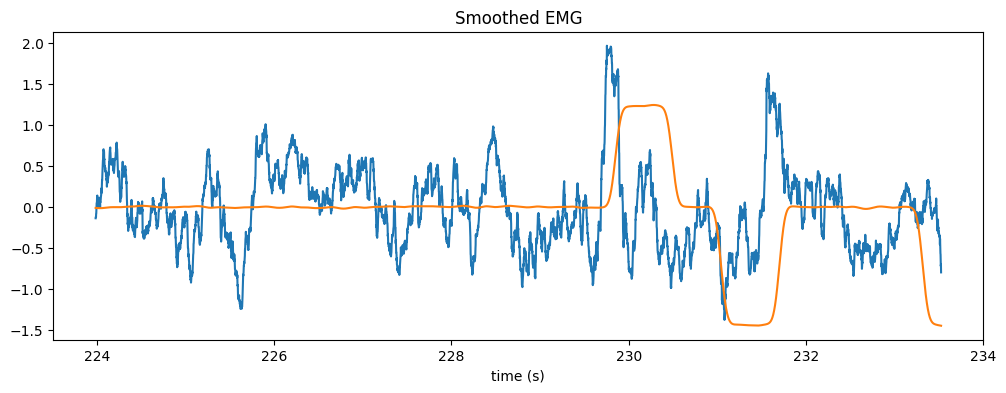

In [152]:
plot_emg_vs_joystick(df["t"],  df["activity"]/10000, df["joy"]/1500)

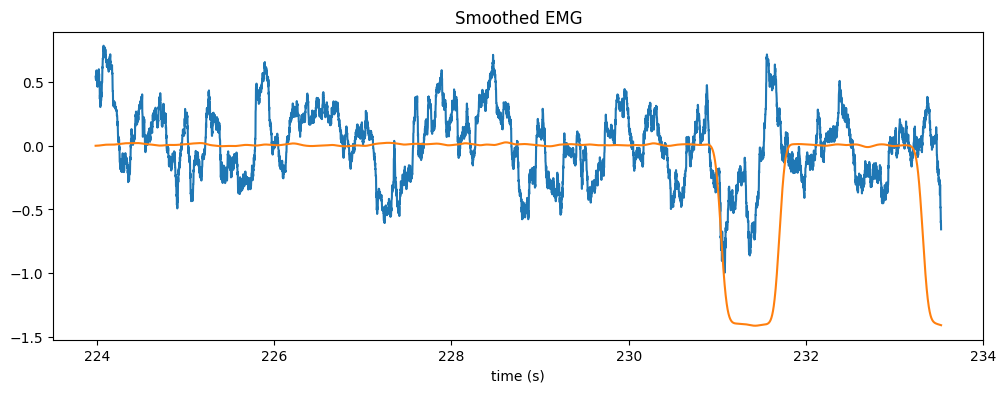

In [153]:
plot_emg_vs_joystick(df["t"],  - (df["flex_rms"]-df["flex_rms"].mean())/10000, df["y_bottom"]/1500)

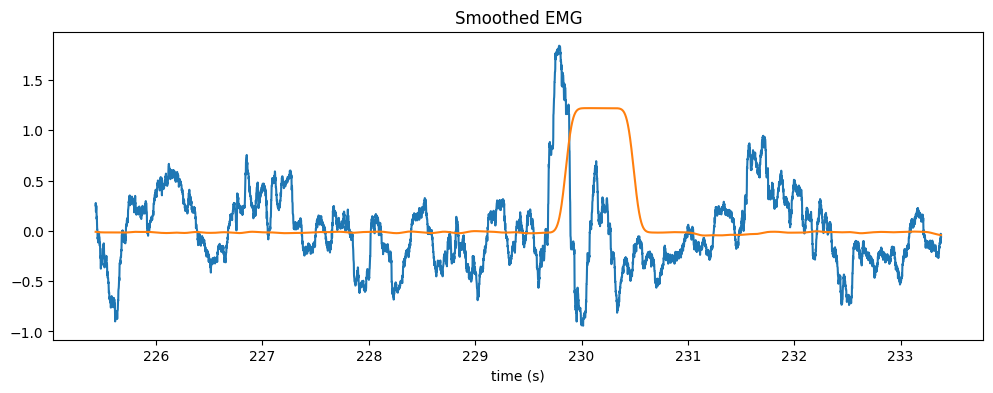

In [149]:
plot_emg_vs_joystick(df["t"],  (df["ext_rms"]-df["ext_rms"].mean())/10000, df["y_top"]/1500)